# Evaluation using a Ground Truth

If a ground truth is provided, one can compare the reconstruction directly with the ground truth as we will do in the following notebook.

## 📦 Imports

In [44]:
import mindmap as mm
import matplotlib.pyplot as plt 
import pygsp as pg

## 🧠 Data

- `eeg`: Preprocessed EEG
- `fwd`: Forward operator
- `cst`: Connectome spectrum transform
- `gt`: Ground Truth

In [45]:
################## Parameters #######################
# configuration
fconfig = "../../papers/simf/configuration.yml"
sub     = 1 
samp    = 3
####################################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "eeg", "fwd", "cst", "sc", "gt", "gt_noise", sample=samp)

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- fwd
- cst
- gt_noise
- sc
- gt
Missing objects:


Let's apply some source reconstruction methods that we will compare to the ground truth.

In [9]:
############ Parameters ##############
methods = ["cset",  "wcset"]
######################################

reconstructions = []

for m in methods:
    if m == "cset":
        stc = mm.cset(data["eeg"], data["fwd"], data["cst"], lam=0.1)
        reconstructions.append(stc)

    if m == "sloreta":
        stc = mm.sloreta(data["eeg"], data["fwd"])
        reconstructions.append(stc)

    if m == "wcset":
        pos = mm.utils.get_src_position(data["fwd"]["src"])
        G   = pg.graphs.Graph(data["sc"], lap_type="normalized", coords=pos)
        G.compute_fourier_basis()

        eigvals = G.e
        weights = mm.utils.harmonic_weights(eigvals, relaxation=0.2)

        stc = mm.wcset(data["eeg"], data["fwd"], data["cst"], weights, lam=0.1)
        reconstructions.append(stc)

2025-06-04 16:26:00,692:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


## Comparison

🌟 **Visually** <br>
To start with, we can compare visually.

🎚️ <font color=violet>**Values**</font> 
- `energy`: Whether to plot energy density. Else, raw data is plotted. 

In [10]:
########### Parameters #############
# values
energy = True 
####################################

images = [data["gt"], data["gt_noise"]] + reconstructions

if energy:
    images = [mm.utils.squared_stc(img) for img in images]
images = [mm.utils.standardize_stc(img, timepoint_wise=True) for img in images]  

mm.viz.plot_brain(data["fwd"]["src"], images, absolute=False, title=["ground truth", "ground truth with noise"]+methods).show()

Widget(value='<iframe src="http://localhost:45743/index.html?ui=P_0x768387fb2ed0_2&reconnect=auto" class="pyvi…

⚙️ <font color=green>**Correlation**</font> <br>
We can compute the spatial correlations (correlation between a reconstruction and the ground truth at each time point).

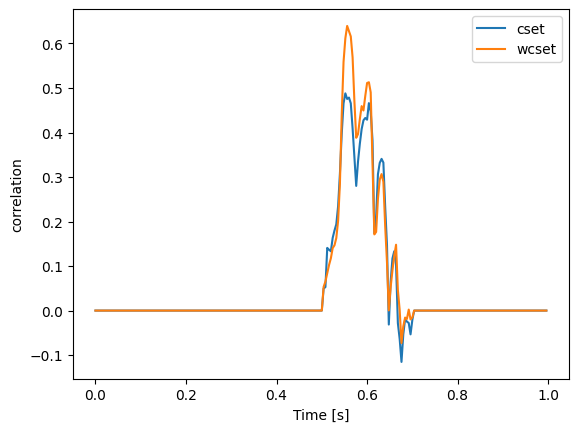

In [11]:
correlations = []
times        = data["gt"].times

# compute correlations over time
for recon in reconstructions:
    corr = mm.utils.compute_stc_correlation(data["gt"], recon, axis="space")
    correlations.append(corr)

# plot correlation
fig = plt.Figure()

for i, m in enumerate(methods):
    plt.plot(times, correlations[i])

plt.xlabel("Time [s]")
plt.ylabel("correlation")
plt.legend(methods)
plt.show()

In [53]:
times = data["eeg"].times
times = times[(times>=0.5) & (times<0.63)]
print(times)


[0.5   0.504 0.508 0.512 0.516 0.52  0.524 0.528 0.532 0.536 0.54  0.544
 0.548 0.552 0.556 0.56  0.564 0.568 0.572 0.576 0.58  0.584 0.588 0.592
 0.596 0.6   0.604 0.608 0.612 0.616 0.62  0.624 0.628]


In [54]:
eeg = data["eeg"].crop(0.5, 0.63, include_tmax=False)
print(eeg.times)

[0.5   0.504 0.508 0.512 0.516 0.52  0.524 0.528 0.532 0.536 0.54  0.544
 0.548 0.552 0.556 0.56  0.564 0.568 0.572 0.576 0.58  0.584 0.588 0.592
 0.596 0.6   0.604 0.608 0.612 0.616 0.62  0.624 0.628]


/tmp/ipykernel_4707/1312402629.py:1: RuntimeWarning: tmax is not in time interval. tmax is set to <class 'mne.evoked.Evoked'>.tmax (0.628 s)
  eeg = data["eeg"].crop(0.5, 0.63, include_tmax=False)
